# Exploratory data analysis of the modelling table

This notebook describes `mart_person_year`, the table the models in M3 onwards are fitted on. It has one row
per person-year for 2022 and 2023, 40,210 rows in all (21,747 in 2022 and 18,463 in 2023). It uses
aggregated tables only and shows no person-level rows.

**Source.** AHRQ, Medical Expenditure Panel Survey (MEPS), Household Component, full-year consolidated files
HC-243 (2022) and HC-251 (2023), with the inpatient, outpatient and office-based event files.

**What the table holds.**

- **Population.** People with a positive survey weight. Zero-weight people are held out (decision log,
  2026-11-01).
- **Exposure.** Years in scope, from the reference periods of the survey rounds. A full year is 1.
- **Claims.** PMI-scope events under the approved definition (inpatient stays except births and stays that
  began in the emergency room, plus specialist and similar outpatient and office-based visits). A claim is
  one event.
- **Claim cost.** Event payments from all sources. 2022 costs are on-levelled to 2023 prices with the
  PCE-Health price index (factor 1.026).
- **Rates used below.** Frequency is claims per exposure year. Severity is cost per claim. Pure premium is
  cost per exposure year. All use 2023 prices.

Counts are unweighted, as the models are. Frequencies are at a US utilisation level and are not meant to look
like a UK private medical insurance book. The models in M3 work with relativities.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from health_pricing import eda

plt.rcParams.update(
    {"figure.figsize": (7, 3.6), "axes.spines.top": False, "axes.spines.right": False}
)
pd.options.display.float_format = "{:,.3f}".format
con = eda.connect()

## Data dictionary

Every column of `mart_person_year` is defined below, with the MEPS variables it comes from, how it was derived
and the decision log entry behind it. The table is generated from the descriptions in the dbt `schema.yml`
(`_docs/data-dictionary.md`), so it always matches the model.

- **Levels.** `not_applicable` means the question did not apply, for example a child under 18 on an adult-only
  question. `unknown` means an adult who was not asked or whose answer is missing. A null means refused, don't
  know or cannot be computed.
- **Roles.** Rating factor candidates are age, region, coverage, health status, smoking, exercise and the
  condition flags. Sex, the source flags, `left_survey_early` and the survey design variables are for analysis
  only and are never rating factors.

In [2]:
from IPython.display import Markdown

from health_pricing import data_dictionary

Markdown(data_dictionary.render_table())

| Name | Description | Source variables | Derivation | Decision reference |
|---|---|---|---|---|
| `DUPERSID` | Person identifier, the household identifier followed by the person number. Text. A person who is in both years has the same value in both rows. | DUPERSID (2022 and 2023) | none | 2026-10-31 MEPS variable shortlist and 2022-23 mapping (decision gate 1) |
| `DUID` | Household identifier, a number. All members of a household share it. The 2022 train and test split is made on this column, so a household is never on both sides. | DUID (2022 and 2023) | none | 2026-11-01 Household-grouped split within 2022 (issue #18) |
| `year` | Survey year of the row, 2022 or 2023. Together with DUPERSID it identifies a row. | none, set from the file (HC-243 is 2022 and HC-251 is 2023) | A constant added in the staging models stg_fyc_2022 and stg_fyc_2023. | 2026-10-31 Time periods and validation design |
| `split` | Which part of the data the row belongs to. Valid values are train, test and out_of_time. Every 2023 row is out_of_time. A 2022 household is train for about 80 percent of households and test for the rest. | DUID (2022 rows), year | 2023 rows are out_of_time. For 2022 the first 8 hex digits of md5(DUID \|\| '\|split-v1'), read as a number modulo 100, give train below 80 and test otherwise (macro household_split). There is no random state. | 2026-11-01 Household-grouped split within 2022 (issue #18) |
| `age` | Age in whole years at 31 December, from 0 to 85. 85 means 85 or older, because AHRQ caps the value. For a person who left the survey part-way through the year it is the age at the last round they were eligible. Never missing in this table. age_source says which applies. | AGE22X (2022), AGE23X (2023), AGELAST (2022 and 2023, fallback) | The year-end age where it is valid (0 or more). Otherwise AGELAST, the age at the last eligible round, for people whose year-end age is -1 because they left part-way. | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `region` | US census region. 1 is Northeast, 2 is Midwest, 3 is South and 4 is West. Stored as a number. For a person who left part-way it is the region in the latest round that has one. Never missing in this table. region_source says which applies. | REGION22 (2022), REGION23 (2023), then REGION53, REGION42 and REGION31 (both years, fallbacks) | The year-end region where it is 1 to 4. Otherwise the first valid value of REGION53, REGION42 and REGION31, in that order, for people whose year-end region is -1. | 2026-11-01 Region for people who left part-way, and the pre-approved pattern (follow-up under #14) |
| `inscov` | Health insurance coverage during the year. 1 is any private, 2 is public only and 3 is uninsured. Stored as a number. Never missing in this table. | INSCOV22 (2022), INSCOV23 (2023) | Reserved codes -15, -8, -7 and -1 become null. No row has one. | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `rthlth` | Perceived health status. 1 is excellent, 2 very good, 3 good, 4 fair and 5 poor. Stored as a number. It is the answer in the latest round that has a valid one. Missing for a small number of people with no valid answer in any round. | RTHLTH53, RTHLTH42, RTHLTH31 (both years) | The first valid value (1 to 5) of round 5/3, then 4/2, then 3/1. Reserved codes are not valid, so they fall through to the earlier round or give null. | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `mnhlth` | Perceived mental health status. 1 is excellent, 2 very good, 3 good, 4 fair and 5 poor. Stored as a number. It is the answer in the latest round that has a valid one. Missing for a small number of people with no valid answer in any round. | MNHLTH53, MNHLTH42, MNHLTH31 (both years) | The first valid value (1 to 5) of round 5/3, then 4/2, then 3/1. Reserved codes are not valid, so they fall through to the earlier round or give null. | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `OFTSMK53` | How often the person smokes cigarettes, asked of adults in round 5/3. Text levels. 1 is every day, 2 some days and 3 not at all. not_applicable means a child under 18, who was not asked. unknown means an adult who was not asked, for example someone who left before the round. Null means refused, don't know or cannot be computed. The unknown level may act as a leaver indicator, so it is checked for leakage before any use in a rating structure. | OFTSMK53 (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. Other codes keep their value as text (macro category_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `PHYEXE53` | Whether the person does moderate or vigorous physical exercise five times a week, asked of adults in round 5/3. Text levels. 1 is yes and 0 is no. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | PHYEXE53 (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `HIBPDX` | High blood pressure diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | HIBPDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `CHDDX` | Coronary heart disease diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | CHDDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `ANGIDX` | Angina diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | ANGIDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `MIDX` | Heart attack (myocardial infarction) diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | MIDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `OHRTDX` | Other heart disease diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | OHRTDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `STRKDX` | Stroke diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | STRKDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `CHOLDX` | High cholesterol diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | CHOLDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `CANCERDX` | Cancer diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | CANCERDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `ARTHDX` | Arthritis diagnosis, asked of adults. Text levels. 1 is diagnosed and 0 is not. not_applicable means a child under 18. unknown means an adult who was not asked. Null means refused, don't know or cannot be computed. | ARTHDX (2022 and 2023) | -1 becomes not_applicable when age is under 18 and unknown otherwise. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `ASTHDX` | Asthma diagnosis, asked at any age. Text levels. 1 is diagnosed and 0 is not. unknown means the person was not asked. There is no not_applicable level. Null means refused, don't know or cannot be computed. | ASTHDX (2022 and 2023) | -1 becomes unknown for everyone. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `DIABDX_M18` | Diabetes diagnosis, asked at any age. Text levels. 1 is diagnosed and 0 is not. unknown means the person was not asked. There is no not_applicable level. Null means refused, don't know or cannot be computed. | DIABDX_M18 (2022 and 2023) | -1 becomes unknown for everyone. -7, -8 and -15 become null. 1 becomes '1' and 2 becomes '0' (macro yes_no_level). | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `SEX` | Sex as recorded in the survey. 1 is male and 2 is female. Stored as a number. For analysis only. It is not a permitted rating factor. | SEX (2022 and 2023) | Reserved codes -15, -8, -7 and -1 become null. No row has one. | 2026-11-01 Modelling table and rating factor candidates (issue #17) |
| `age_source` | Where age came from. year_end means the year-end age was valid. last_eligible means it was not, so age is the age at the last eligible round. For analysis only. | AGE22X (2022), AGE23X (2023), AGELAST | year_end when the year-end age is 0 or more, else last_eligible. | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `age_topcoded` | True when age is 85, which means 85 or older because AHRQ caps the value. False otherwise. For analysis only. | AGE22X (2022), AGE23X (2023), AGELAST | True when the cleaned age equals 85. | 2026-11-01 Reserved-code treatment (issue #12) and AGELAST added to the shortlist |
| `region_source` | Where region came from. year_end means the year-end region was valid. last_round means it was not, so region is the one in the latest round that has a valid value. For analysis only. | REGION22 (2022), REGION23 (2023), REGION53, REGION42, REGION31 | year_end when the year-end region is 1 to 4, else last_round. | 2026-11-01 Region for people who left part-way, and the pre-approved pattern (follow-up under #14) |
| `left_survey_early` | True when the person was no longer eligible at the end of the year, which is why their year-end age and region were -1. It equals age_source = last_eligible in both years. For analysis only. It must never be used as a rating factor. | ELGRND22 (2022), ELGRND23 (2023) | True when the year-level eligibility status ELGRND equals 3, "person is not eligible". | 2026-11-01 Region for people who left part-way, and the pre-approved pattern (follow-up under #14) |
| `VARSTR` | Variance estimation stratum from the survey design, a number from 2001 to 2117. For analysis only. It is not a rating factor. | VARSTR (2022 and 2023) | none | 2026-11-01 Modelling table and rating factor candidates (issue #17) |
| `VARPSU` | Variance estimation primary sampling unit within the stratum, a number from 1 to 8 in 2022 and 1 to 6 in 2023. For analysis only. It is not a rating factor. | VARPSU (2022 and 2023) | none | 2026-11-01 Modelling table and rating factor candidates (issue #17) |
| `er_stay_count` | Number of inpatient stays in the year that began in the emergency room and were not birth related. These stays are not in claim_count under the approved claim definition. Kept for the M5 sensitivity. Zero when there are none. For analysis only. | Inpatient stay files HC-239D (2022) and HC-248D (2023), EMERROOM and RSNINHOS | Count of stays with EMERROOM = 1 and RSNINHOS not 4, 5 or 6 (birth and pregnancy), per person-year. Zero when the person has no such stay. | 2026-11-01 PMI-scope claim definition (decision gate 2, approved) |
| `er_stay_cost` | Total payments, in dollars of the survey year, for the stays counted in er_stay_count. Zero when there are none. 2022 values are at 2022 prices. For analysis only. | Inpatient stay files HC-239D (2022) and HC-248D (2023), IPXP22X and IPXP23X | Sum of the stay expenditure over the stays counted in er_stay_count. No price adjustment. | 2026-11-01 PMI-scope claim counts and on-levelled costs (issues #15 and #16) |
| `er_stay_cost_2023_prices` | er_stay_cost in 2023 dollars. 2022 values are multiplied by 1.02599 and 2023 values are unchanged. For analysis only. | Inpatient stay files (IPXP22X, IPXP23X) and the PCE-Health price index (data/reference/pce_health.csv) | er_stay_cost times the on-level factor, 113.121 / 110.256 for 2022 and 1 for 2023. | 2026-11-01 PMI-scope claim counts and on-levelled costs (issues #15 and #16) · 2026-11-01 Price index for on-levelling and projection (decision gate 4, part 1, confirmed) |
| `exposure` | Years the person was in scope in the calendar year, from 1/12 to 1. Counted in whole months, divided by 12. A full year is 1. Part-year exposure comes from births, deaths, late entry, gaps and leaving the survey. Always above 0 in this table. | BEGRFM, BEGRFY, ENDRFM, ENDRFY and ELGRND for rounds 31, 42 and 53 (both years) | A calendar month counts when it lies inside the reference period of a round in which the person is eligible (ELGRND = 1). Months shared by two rounds count once. Exposure is the months counted divided by 12. | 2026-11-01 Exposure derivation (issue #13) |
| `claim_count` | Number of PMI-scope claims in the year, 0 or more. A claim is one in-scope event record from the inpatient, hospital outpatient or office-based event files. Zero when the person has none. Emergency-room-originated stays are not counted, see er_stay_count. | Event files HC-239D, HC-239F and HC-239G (2022) and HC-248D, HC-248F and HC-248G (2023) | Count of events that meet the PMI-scope rule for their file, per person-year. Inpatient stays count unless they are birth related or began in the emergency room. Outpatient and office-based visits count when the provider qualifies and the visit category is not excluded. | 2026-11-01 PMI-scope claim definition (decision gate 2, approved) · 2026-11-01 PMI-scope claim counts and on-levelled costs (issues #15 and #16) |
| `claim_cost` | Total payments, in dollars of the survey year, for the claims counted in claim_count, from all payment sources. Zero when there are no claims. 2022 values are at 2022 prices. | Event expenditure IPXP22X, OPXP22X and OBXP22X (2022) and IPXP23X, OPXP23X and OBXP23X (2023) | Sum of the event expenditure over the in-scope events. No price adjustment. | 2026-11-01 PMI-scope claim counts and on-levelled costs (issues #15 and #16) |
| `claim_cost_2023_prices` | claim_cost in 2023 dollars. 2022 values are multiplied by 1.02599 and 2023 values are unchanged. This is the cost the severity models use. | Event expenditure (as for claim_cost) and the PCE-Health price index (data/reference/pce_health.csv) | claim_cost times the on-level factor, 113.121 / 110.256 for 2022 and 1 for 2023. | 2026-11-01 PMI-scope claim counts and on-levelled costs (issues #15 and #16) · 2026-11-01 Price index for on-levelling and projection (decision gate 4, part 1, confirmed) |
| `perwt` | Final person weight from the survey, above 0 for every row in this table. The number of US people the person represents. Used for sanity checks against published figures only. The models are fitted unweighted. | PERWT22F (2022), PERWT23F (2023) | None to the value. Persons with a weight of 0 are held out of the table as a definition of the modelling population. | 2026-11-01 Modelling population and exclusions (issue #14, decision gate 3) |


## Exposure

Most people are in scope for the whole year. The rest are part-year, for example births, deaths and people
who left the survey, and their exposure is counted in whole months.

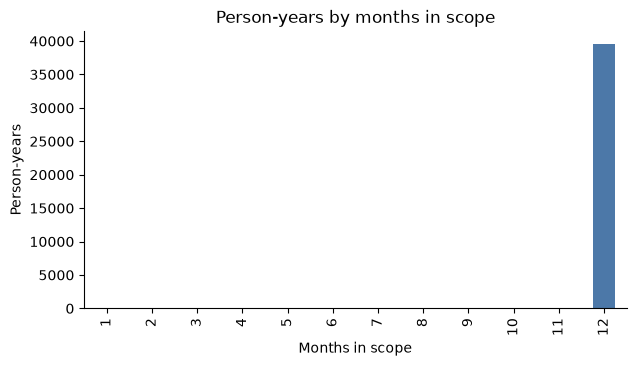

Full-year share of person-years: 98.2%


In [3]:
exposure = eda.exposure_distribution(con)
ax = exposure.plot.bar(x="months", y="persons", legend=False, color="#4c78a8")
ax.set_title("Person-years by months in scope")
ax.set_xlabel("Months in scope")
ax.set_ylabel("Person-years")
plt.show()
share = exposure.loc[exposure["months"] == 12, "persons"].sum() / exposure["persons"].sum()
print(f"Full-year share of person-years: {share:.1%}")

## Zero-claim share

Most people have no PMI-scope claim in a year. This is why the frequency models use an exposure offset and why
severity is fitted on claimants only.

In [4]:
zero = eda.zero_claim_share(con)
zero

,year,persons,zero_claim,zero_claim_share
0,2022,21747,12787,0.588
1,2023,18463,10646,0.577


## Frequency and severity by age band

Frequency rises steeply with age, from about one claim per year for children and young adults to more than six
for people aged 75 and over. Severity rises more slowly and flattens after the late fifties. The pure premium
therefore follows frequency most of the way.

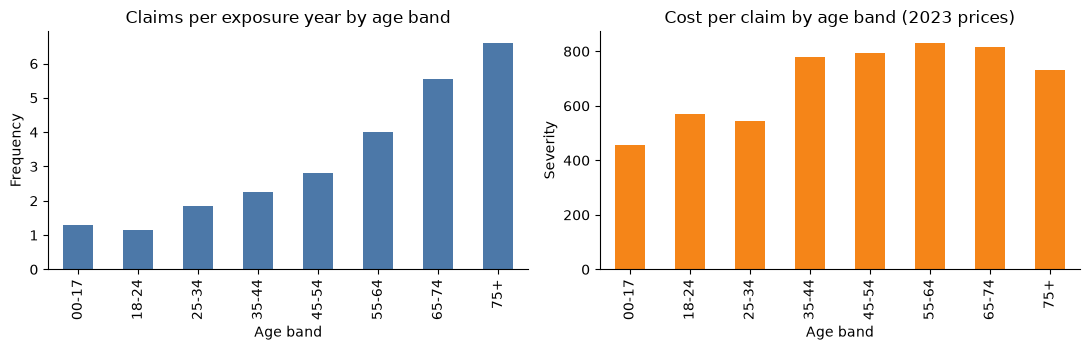

,age_band,persons,exposure,claim_count,frequency,severity,pure_premium
0,00-17,7730,"7,594.167","9,807.000",1.291,458.108,591.595
1,18-24,2677,"2,659.750","3,025.000",1.137,571.233,649.677
2,25-34,4380,"4,369.750","8,052.000",1.843,545.609,"1,005.376"
3,35-44,5001,"4,991.333","11,301.000",2.264,780.623,"1,767.428"
4,45-54,4805,"4,797.750","13,530.000",2.820,794.211,"2,239.733"
5,55-64,5687,"5,666.417","22,668.000",4.000,831.728,"3,327.254"
6,65-74,5696,"5,645.583","31,370.000",5.557,816.656,"4,537.794"
7,75+,4234,"4,117.583","27,213.000",6.609,730.542,"4,828.130"


In [5]:
age = eda.by_age_band(con)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
age.plot.bar(x="age_band", y="frequency", ax=axes[0], legend=False, color="#4c78a8")
axes[0].set_title("Claims per exposure year by age band")
axes[0].set_xlabel("Age band")
axes[0].set_ylabel("Frequency")
age.plot.bar(x="age_band", y="severity", ax=axes[1], legend=False, color="#f58518")
axes[1].set_title("Cost per claim by age band (2023 prices)")
axes[1].set_xlabel("Age band")
axes[1].set_ylabel("Severity")
plt.tight_layout()
plt.show()
age[["age_band", "persons", "exposure", "claim_count", "frequency", "severity", "pure_premium"]]

## Frequency and severity by sex and region

Sex is shown for analysis only. It is not a permitted rating factor and the final rating structure excludes it.
Women have a higher frequency and a lower severity than men, and the pure premium is close. Region differs more
in frequency than in severity, with the Northeast highest.

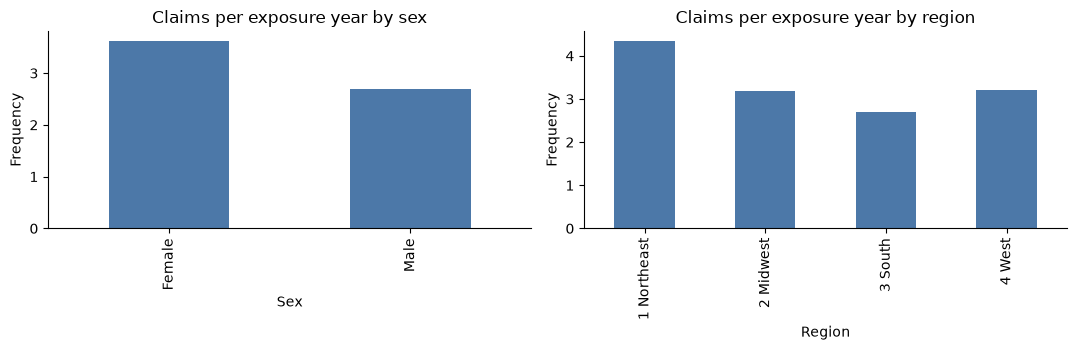

,level,persons,exposure,claim_count,frequency,severity,pure_premium
0,Female,21167,"20,991.250","76,099.000",3.625,679.687,"2,464.049"
1,Male,19043,"18,851.083","50,867.000",2.698,841.611,"2,270.970"
0,1 Northeast,6258,"6,205.000","26,999.000",4.351,685.863,"2,984.305"
1,2 Midwest,8171,"8,096.167","25,820.000",3.189,807.688,"2,575.849"
2,3 South,15646,"15,495.000","41,989.000",2.710,766.648,"2,077.495"
3,4 West,10135,"10,046.167","32,158.000",3.201,714.311,"2,286.525"


In [6]:
sex = eda.by_sex(con)
region = eda.by_region(con)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sex.plot.bar(x="sex", y="frequency", ax=axes[0], legend=False, color="#4c78a8")
axes[0].set_title("Claims per exposure year by sex")
axes[0].set_xlabel("Sex")
axes[0].set_ylabel("Frequency")
region.plot.bar(x="region", y="frequency", ax=axes[1], legend=False, color="#4c78a8")
axes[1].set_title("Claims per exposure year by region")
axes[1].set_xlabel("Region")
axes[1].set_ylabel("Frequency")
plt.tight_layout()
plt.show()
pd.concat([sex.rename(columns={"sex": "level"}), region.rename(columns={"region": "level"})])[
    ["level", "persons", "exposure", "claim_count", "frequency", "severity", "pure_premium"]
]

## Frequency by condition flag

These are adults with an answered flag only. People who were not asked, who refused or who did not know are left
out here. Each diagnosed condition has a clearly higher frequency than the group without it, which is the signal
a full medical underwriting structure would use. Part of the gap is age, because older people are more likely to
have a condition, and the GLMs in M3 handle that.

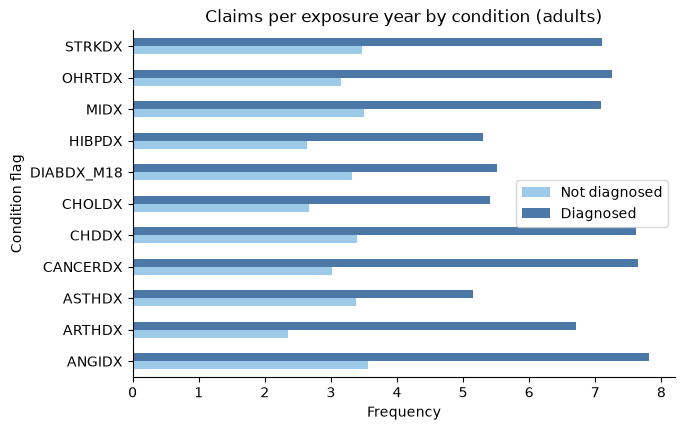

persons            frequency      
level               0          1         0     1
condition                                       
ANGIDX     31,569.000    642.000     3.561 7.817
ARTHDX     22,597.000  9,611.000     2.353 6.704
ASTHDX     27,722.000  4,679.000     3.380 5.143
CANCERDX   27,814.000  4,397.000     3.021 7.640
CHDDX      30,256.000  1,951.000     3.393 7.609
CHOLDX     20,641.000 11,539.000     2.671 5.401
DIABDX_M18 27,796.000  4,604.000     3.323 5.519
HIBPDX     19,909.000 12,292.000     2.634 5.299
MIDX       30,915.000  1,307.000     3.503 7.083
OHRTDX     28,263.000  3,954.000     3.146 7.247
STRKDX     30,620.000  1,597.000     3.469 7.108

In [7]:
condition = eda.by_condition(con)
wide = condition.pivot(index="condition", columns="level", values="frequency")
ax = wide.plot.barh(color={"0": "#9ecae9", "1": "#4c78a8"}, figsize=(7, 4.5))
ax.set_title("Claims per exposure year by condition (adults)")
ax.set_xlabel("Frequency")
ax.set_ylabel("Condition flag")
ax.legend(["Not diagnosed", "Diagnosed"], title=None)
plt.show()
condition.pivot(index="condition", columns="level", values=["persons", "frequency"])

## Distribution of annual claim cost

Claimants only, on a log scale. The distribution is skewed, with a long right tail, which is why the severity
model uses a Gamma family with a log link and why large claims need a cap and a separate load in M3.

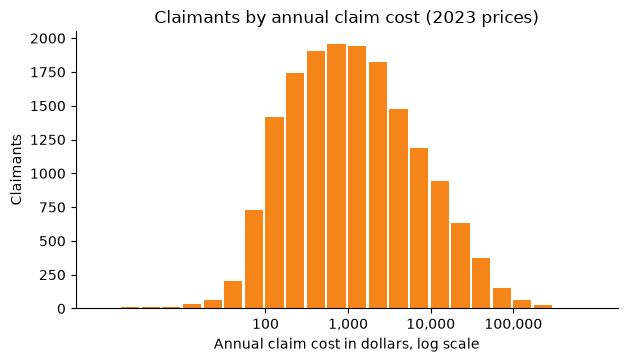

Claimants: 16,683


In [8]:
cost = eda.claim_cost_distribution(con)
ax = plt.subplot()
ax.bar(cost["log10_low"], cost["claimants"], width=0.22, align="edge", color="#f58518")
ax.set_title("Claimants by annual claim cost (2023 prices)")
ax.set_ylabel("Claimants")
ticks = [2, 3, 4, 5]
ax.set_xticks(ticks, [f"{10**t:,.0f}" for t in ticks])
ax.set_xlabel("Annual claim cost in dollars, log scale")
plt.show()
print(f"Claimants: {int(cost['claimants'].sum()):,}")

## Train and test balance

The 2022 split is by household, so no household is on both sides. The out-of-time set is all of 2023. Shares
are within each year. The test share is close to 20 percent on persons, exposure and claim cost, so the test set
is a fair sample of the training data.

In [9]:
balance = eda.split_balance(con)
balance[
    [
        "year",
        "split",
        "persons",
        "persons_share",
        "exposure_share",
        "claim_cost_share",
        "claim_count",
    ]
]

,year,split,persons,persons_share,exposure_share,claim_cost_share,claim_count
0,2022,test,4151,0.191,0.190,0.204,"12,463.000"
1,2022,train,17596,0.809,0.810,0.796,"53,322.000"
2,2023,out_of_time,18463,1.000,1.000,1.000,"61,181.000"


## What this means for the models

- **Frequency.** Age and the condition flags are the strongest signals. The exposure offset is needed, because
  about 2 percent of person-years are part-year.
- **Severity.** Fit on the claimants only. The tail is long, so cap large claims and load for them separately.
- **Limits.** The data are US survey data, the claim definition uses event type, provider and visit category,
  and about 40 percent of people have a claim in a year. See the decision log and the reconciliation note for
  the reasoning and checks.